In [1]:
using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
include("run_sim.jl")
include("run_sim_optim_constant_inh.jl")
include("conv_spikes.jl") 
# include("firing_rates_max.jl") 


conv_spikes (generic function with 1 method)

## Trial

In [2]:
function conv_spikes(array, pos1,pos2)

    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array[pos1,:], hanning_window);# Convolve the spike arrays with the Gaussian window
    smoothed_spike_array2 = conv(array[pos2,:], hanning_window);

    # Because convolution extends the length of the array,let's truncate it to the original length
    len = length(array[1,:]);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];

return smoothed_spike_array1, smoothed_spike_array2
end
# smoothed_spike_array1,smoothed_spike_array2= conv_spikes(spike_array, 47,48)

conv_spikes (generic function with 1 method)

In [3]:
dr_1_2= [smoothed_spike_array1 smoothed_spike_array2];

x = range(0, stop=maximum(smoothed_spike_array2), length=length(smoothed_spike_array1)); 
y_values = LinRange(0., maximum(smoothed_spike_array1), length(smoothed_spike_array1));
x_values = zeros(length(y_values));
vertical_line = hcat(x_values, y_values); #this is the line that would make us achieve flexible control

Plots.plot(dr_1_2[:,2],dr_1_2[:,1])
Plots.plot!(dr_1_2[300000:600000,2],dr_1_2[300000:600000,1],color= :red)



# Plots.plot!(vertical_line[:,1],vertical_line[:,2])

UndefVarError: UndefVarError: smoothed_spike_array1 not defined

In [ ]:
what=  dr_1_2[:,1] - dr_1_2[:,2]
histogram(what)
Plots.xlims!(-0.00005, 0.0006)


## Functions for the control algorithm

In [2]:
function run_sim_optim_constant_inh(MN_list,i)
    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end

# function run_sim_optim_constant_inh()
#     for i in 1:nr_s
#         # temp = filter_input(50,rand(Normal(0, 1),sim_length+2000))  # add some gaussian noise - optional
#         # independantnoise[i,:] = temp[1001:end-1000] * 0.25;
#         full_input[i,:] = commoninput  + independantnoise[i,:]; 
#         vd, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input[i,:], inh_input, MNs)      
#         spikes = spikes_from_aps(vs, i, MNs)       
#         spike_arr[i,:] = spikes
#         vs_arr[i,:] = vs
#     end
#     return spike_arr, vs_arr
# end


function conv_spikes_rates(array1,array2)
    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array1[1,:], hanning_window);# Convolve the spike arrays with the Gaussian window
    smoothed_spike_array2 = conv(array2[1,:], hanning_window);

    # Because convolution extends the length of the array, let's truncate it to the original length
    len = size(array1,2);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];
    print("")

return smoothed_spike_array1, smoothed_spike_array2
end
   

conv_spikes_rates (generic function with 1 method)

## Init control algorithm

In [3]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hystprofile_NEW.jld2" γn_new
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCa_LAST_gamma07.jld2" VthCa_new


# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 

Vthca_S = VthCa_new
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7#γn_new
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;


tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function


full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);


In [4]:
mn1=44; mn2=47
commoninput = tr
spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)  
spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)  

([0 0 … 0 0], [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])

In [5]:
smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;


# Plots.plot(trajectory2_controlled[:,1],trajectory2_controlled[:,1])  # Controlled trajectory from neurons)


30000×2 Matrix{Float64}:
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 ⋮    
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0

In [6]:
y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2]);
x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]));
trajectory1 = hcat(x_values, y_values) ; # This is the line that would make us achieve flexible control;

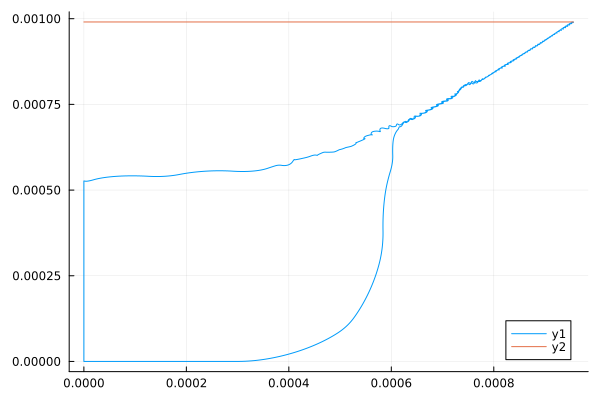

In [7]:
# Plots.plot(trajectory2_controlled[1:15000,1],trajectory2_controlled[1:15000,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory2_controlled[15000:30000,1],trajectory2_controlled[15000:30000,2])  # Controlled trajectory from neurons)
Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2])  # Controlled trajectory from neurons)

Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)


In [143]:
maximum(new_avg[20800:21000,2])

0.00028417525549122676

## Control algorithm

In [40]:
# Control parameters
kp = Float32(4)  # Example of increasing the proportional gain  #0.9
kd = Float32(0.2)  # Example of increasing the derivative gain #0.2
dt = Float32(0.1) 

mn1 = 44
mn2 = 47


previous_error= 0.0

tr_new = copy(tr)
vthca_1= copy(MN_list[mn1][:VthCa])
vthca_2= copy(MN_list[mn2][:VthCa])


threshold = 0.3  # The threshold value for penalizing


for iteration in 1:50

    commoninput = tr_new  

    MN_list[mn1][:VthCa]= vthca_1
    MN_list[mn2][:VthCa]= vthca_2

    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1) 
    spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)  

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg #avg every 20 points
    

    # Trajectory we want to achieve (for flexibility)
    y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2])
    x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    trajectory1 = hcat(x_values, y_values)  


    start= Int(size(trajectory1, 1)/2)

    for i in start:size(trajectory1, 1) 

        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        euclidean_error = sqrt(error1^2 + error2^2)
     
        #ERRORS FROM CONTROL OUTPUT
        # integral_error += euclidean_error * dt  
        derivative_error = (euclidean_error - previous_error) / dt
        control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 
        
        
        # if tr_new[i] + control_output > threshold
        #     control_output *= 0.9  # more gradual penalty
        # end
        

        tr_new[i] += control_output  
        
        
        previous_error = euclidean_error

    end

    
end


In [155]:
# Define control parameters
kp_tr = Float32(4)  # Proportional gain for tr
kd_tr = Float32(0.2)  # Derivative gain for tr
kp_vthca = 0.2  # Proportional gain for vthca (example value, adjust as needed)
kd_vthca = Float32(0.1)  # Derivative gain for vthca (example value, adjust as needed)
dt = Float32(0.1)

mn1 = 44
mn2 = 47

previous_error_tr = 0.0
previous_error_vthca1 = 0.0
previous_error_vthca2 = 0.0

tr_new = copy(tr)
vthca_1 = copy(MN_list[mn1][:VthCa])
vthca_2 = copy(MN_list[mn2][:VthCa])

# Define VthCa limits
vthca_min = 0.0
vthca_max = 10.0

threshold = 0.3  # The threshold value for penalizing

for iteration in 1:20

    commoninput = tr_new

    MN_list[mn1][:VthCa] = vthca_1
    MN_list[mn2][:VthCa] = vthca_2

    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)
    spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg # avg every 20 points

    # Trajectory we want to achieve (for flexibility)
    y_values = ones(length(trajectory2_controlled[:, 2])) * maximum(trajectory2_controlled[:, 2])
    x_values = range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    trajectory1 = hcat(x_values, y_values)

    start = Int(size(trajectory1, 1) / 2)

    for i in start:size(trajectory1, 1)

        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        euclidean_error = sqrt(error1^2 + error2^2)

        # Control for tr_new
        derivative_error_tr = (euclidean_error - previous_error_tr) / dt
        control_output_tr = kp_tr * euclidean_error + kd_tr * derivative_error_tr
        tr_new[i] += control_output_tr

        # Conditionally adjust vthca_1 if needed
        if euclidean_error > previous_error_vthca1
            derivative_error_vthca1 = (euclidean_error - previous_error_vthca1) / dt
            control_output_vthca1 = kp_vthca * euclidean_error + kd_vthca * derivative_error_vthca1
            vthca_1 += control_output_vthca1
            vthca_1 = clamp(vthca_1, vthca_min, vthca_max)
        end

        # Conditionally adjust vthca_2 if needed
        if euclidean_error > previous_error_vthca2
            derivative_error_vthca2 = (euclidean_error - previous_error_vthca2) / dt
            control_output_vthca2 = kp_vthca * euclidean_error + kd_vthca * derivative_error_vthca2
            vthca_2 += control_output_vthca2
            vthca_2 = clamp(vthca_2, vthca_min, vthca_max)
        end


        previous_error_tr = euclidean_error
        previous_error_vthca1 = euclidean_error
        previous_error_vthca2 = euclidean_error

    end
end


In [157]:
vthca_2

10.0

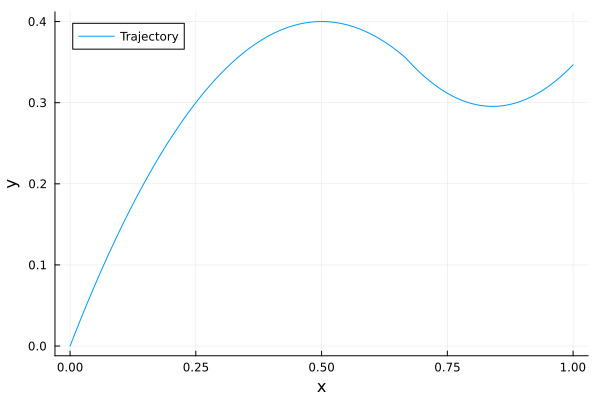

In [129]:
#### parabola for checking what happens

total_length = 30000
max_amplitude = 0.4
half_length = div(total_length, 2)

x1 = range(0, stop=1, length=total_length)[1:20000]
a1 = -max_amplitude * 4
h1 = 0.5
k1 = max_amplitude
y1 = a1 * (x1 .- h1) .^ 2 .+ k1


x2_start = x1[end]
x2 = range(x1[end], stop=1, length=total_length-length(x1))#[1:5000]
a2 = max_amplitude * 5
h2 = 0.84
k2 = y1[end]  # Start at the end point of the first parabola
y2 = a2 * (x2 .- h2) .^ 2 .+ (k2 - a2 * (x2_start - h2)^2)


# y3 = fill(y2[end], 5000)
# x3 = range(x2[end], stop=1, length=total_length-length(x1)-length(x2))

# up = range(y3[end], stop=amplitude, length=2500)
# upx = range(x3[end], stop=1, length=2500)

trajectory = vcat(y1, y2)#,y3)
trajectory_x = vcat(x1, x2)#,x3)


# Plots.plot(x2, y2, label="Trajectory", xlabel="x", ylabel="y")

Plots.plot(trajectory_x, trajectory, label="Trajectory", xlabel="x", ylabel="y")

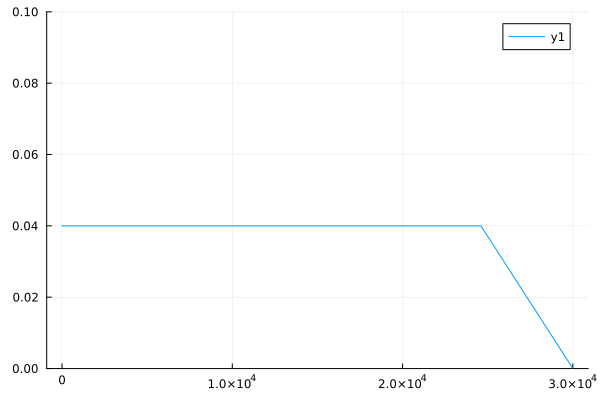

In [46]:
inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0., length=5400)
inh_input = vcat(inh,down)
Plots.plot([1:30000],inh_input,ylim=[0,0.1])

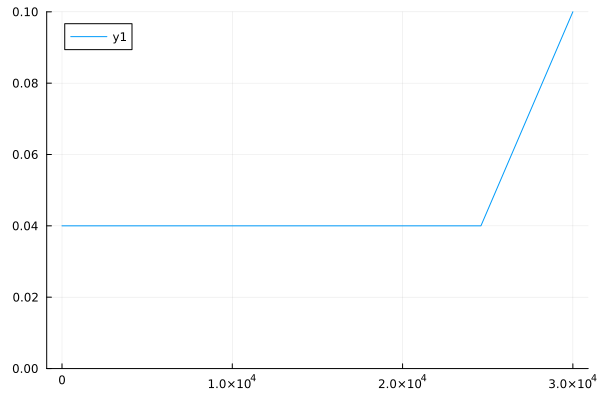

In [111]:
inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0.1, length=5400)
inh_input = vcat(inh,down)
Plots.plot([1:30000],inh_input,ylim=[0,0.1])

In [89]:
# Control parameters
kp = Float32(0.9)  # Proportional gain
kd = Float32(0.3)  # Derivative gain
ki = Float32(0.1)  # Integral gain

dt = Float32(0.1)
previous_error = 0.0
integral_error = 0.0  # Initialize integral error

tr_new = copy(tr)
threshold = 0.2  # The threshold value for penalizing

mn1 = 44
mn2 = 47

# Logging arrays
error_log = []
control_output_log = []

for iteration in 1:100  # Increase number of iterations
    commoninput = tr_new
    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)
    spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg

    # Define the desired trajectory
    y_values = ones(length(trajectory2_controlled[:, 2])) * maximum(trajectory2_controlled[:, 2])
    x_values = range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    trajectory1 = hcat(x_values, y_values)

    start = Int(size(trajectory1, 1) / 2)

    for i in start:size(trajectory1, 1)
        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        euclidean_error = sqrt(error1^2 + error2^2)

        integral_error += euclidean_error * dt  # Integrate error
        derivative_error = (euclidean_error - previous_error) / dt
        control_output = kp * euclidean_error + kd * derivative_error + ki * integral_error  # Include integral term

        # Apply saturation if control output exceeds threshold
        if tr_new[i] + control_output > threshold
            control_output = control_output / 2  # Apply a penalty by reducing the control output
        end

        tr_new[i] += control_output
        previous_error = euclidean_error

        # Log errors and control outputs for debugging
        push!(error_log, euclidean_error)
        push!(control_output_log, control_output)
    end
end




UndefVarError: UndefVarError: plot not defined

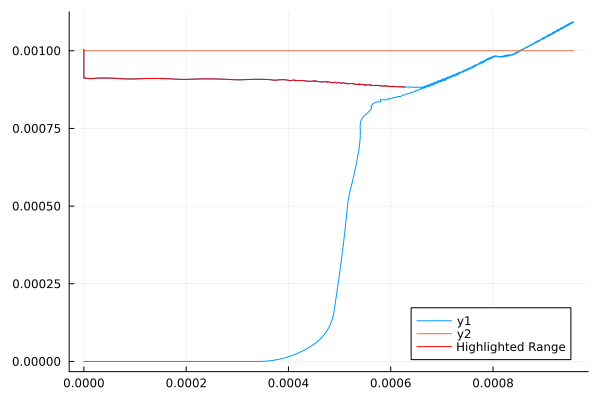

In [132]:
MN_list[44][:VthCa]=0.
MN_list[47][:VthCa]=8.

MN_list[47][:γh]=1.
MN_list[47][:γh]=1.

mn1=44; mn2=47
commoninput = trajectory

inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0.3, length=5400)
inh_input = vcat(inh,down)
spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)  

####

inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0., length=5400)
inh_input = vcat(inh,down)
spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)  

##

smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;


y_values = ones(length(y_values))*0.001
x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control


# Highlight the specific range in red

highlight_range = (25200:30000)
highlight_x = trajectory2_controlled[highlight_range,1]
highlight_y = trajectory2_controlled[highlight_range,2]


# Plots.plot(trajectory2_controlled[1:15000,1],trajectory2_controlled[1:15000,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory2_controlled[15000:30000,1],trajectory2_controlled[15000:30000,2])  # Controlled trajectory from neurons)


Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2])  # Controlled trajectory from neurons)

Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)

Plots.plot!(highlight_x, highlight_y, color=:red, label="Highlighted Range")


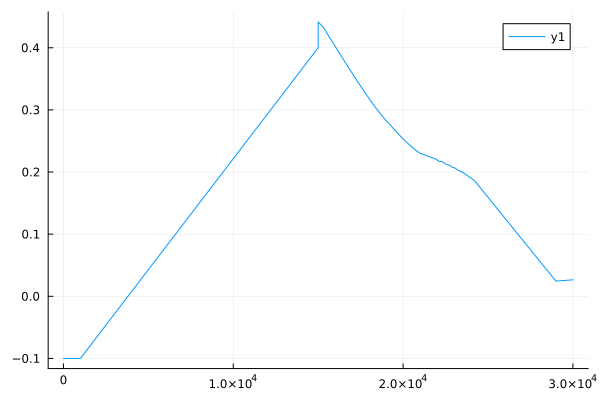

In [153]:
Plots.plot([1:30000],tr_new)